# L11 — Reinforcement Learning
## The recommender that *learns from clicks*

**Bonus lesson (added by learner request) · hands-on code-along · 60–90 minutes** — Parts 1–4 are the core (~70 min); Part 5 is optional (~20 min).

> *Sarah Chen · Customer Experience Analyst · NorthStar Retail · a few months after the L10 launch.*
> Sarah's churn model and shopping assistant are live. Now Marcus wants the homepage to **recommend the right product banner to each visitor** — and to *get better on its own* as real shoppers click. Nobody has a labelled "correct banner" list. The system has to learn by trying.
>
> That last sentence is the whole reason this is a *reinforcement learning* problem, not a supervised one.

---

### How this session works (do first, theory after)

You will **build a working recommender in Part 1 before we explain a single piece of theory.** This is deliberate. Once you have *felt* the agent learn, the vocabulary in Part 3 will click into place much faster than if we'd front-loaded definitions.

| Part | What you do | Learning-cycle stage |
|---|---|---|
| **1. Do it** | Build an agent that learns which banner gets clicks | Concrete experience |
| **2. Look at it** | Read the learning curve, spot the tension | Reflective observation |
| **3. Name it** | The theory, in plain English, mapped back to your code | Abstract concepts |
| **4. Tinker** | Change the dials and see what breaks | Active experimentation |
| **5. (Optional) Go deeper** | Add *context* and meet the Q-table — real RL | Stretch |

**What you need:** only `numpy` and `matplotlib`. No special RL libraries, no GPU. Run every cell top to bottom.

In [1]:
# Run me first. These are the only libraries we need.
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)  # fixed seed so your results match the notes
print("Ready. NorthStar recommender lab is set up.")

Ready. NorthStar recommender lab is set up.


---
# Part 1 — Do it: build a recommender that learns
**⏱ ~25 minutes. No theory yet — just build and watch.**

## The situation

NorthStar's homepage can show **one of three product banners** to each visitor:

- **Banner A** — *"New arrivals"*
- **Banner B** — *"Up to 50% off"*
- **Banner C** — *"Trending now"*

When a visitor lands, we pick one banner to show. The visitor either **clicks** (reward = 1) or **doesn't** (reward = 0). That's the only feedback we get. We do **not** know in advance which banner is best — we have to find out by showing them and watching.

Here's the catch that makes this interesting: every time we show a *worse* banner to learn about it, we (probably) lose a click we could have had. So the recommender has to balance **trying things out** against **cashing in on what it already knows.** Hold that thought — we'll name it properly in Part 3.

In [2]:
# The "real world" — hidden from the agent.
# Each banner has a TRUE click-through rate the agent does NOT know.
# The agent must discover these by showing banners and watching clicks.

true_click_rates = {
    "A · New arrivals": 0.05,   #  5% of visitors click
    "B · 50% off":      0.11,   # 11% of visitors click  <- actually the best
    "C · Trending now": 0.08,   #  8% of visitors click
}
banners = list(true_click_rates.keys())
true_rates = np.array(list(true_click_rates.values()))

def show_banner(banner_index):
    """Show a banner to one visitor. Returns 1 if they clicked, else 0."""
    p = true_rates[banner_index]
    return 1 if rng.random() < p else 0

for name, rate in true_click_rates.items():
    print(f"{name:20s}  true click rate = {rate:.0%}")
print("\n(The agent cannot see these numbers — it only sees clicks.)")

A · New arrivals      true click rate = 5%
B · 50% off           true click rate = 11%
C · Trending now      true click rate = 8%

(The agent cannot see these numbers — it only sees clicks.)


## Approach 1 — the naive baseline: show banners at random

Before anything clever, let's see what happens if the homepage just picks a banner **at random** every time. This is our "do nothing smart" baseline — the number any real method has to beat.

In [3]:
def run_random(n_visitors=5000):
    total_clicks = 0
    for _ in range(n_visitors):
        choice = rng.integers(0, 3)      # pick a banner with no thought
        total_clicks += show_banner(choice)
    return total_clicks

clicks = run_random()
n = 5000
print(f"Random banner choice over {n} visitors:")
print(f"  Total clicks: {clicks}")
print(f"  Click rate:   {clicks/n:.2%}")
print(f"  (Best possible if we always knew to show B: ~{true_rates.max():.0%})")

Random banner choice over 5000 visitors:
  Total clicks: 385
  Click rate:   7.70%
  (Best possible if we always knew to show B: ~11%)


Random leaves a lot of clicks on the table — it shows the weak banners just as often as the strong one. Now let's build something that **learns.**

## Approach 2 — an agent that learns: ε-greedy ("epsilon-greedy")

The idea in one breath: **mostly show the banner that has performed best so far, but every so often try a random one just to keep learning.**

To do that, the agent keeps a simple scoreboard:

- how many times it has shown each banner, and
- the running **average clicks** (the estimated click rate) for each banner.

Before it starts, the agent shows **each banner once** so every banner has at least one data point. After that, `epsilon` is the one dial that controls how often it explores. `epsilon = 0.1` means: *10% of the time pick a random banner to try; the other 90% show the current best.* Don't worry about why yet — build it, run it, then we'll explain.

In [4]:
def run_epsilon_greedy(n_visitors=5000, epsilon=0.1):
    counts = np.zeros(3)            # times each banner was shown
    estimated_rate = np.zeros(3)    # running average click rate per banner
    click_history = []             # 1/0 for each visitor, to plot learning

    for t in range(n_visitors):
        # --- DECIDE which banner to show ---
        if t < 3:
            choice = t                           # WARM-UP: show each banner once
        elif rng.random() < epsilon:
            choice = rng.integers(0, 3)          # EXPLORE: try a random banner
        else:
            choice = int(np.argmax(estimated_rate))  # EXPLOIT: show current best

        # --- ACT and get feedback ---
        reward = show_banner(choice)
        click_history.append(reward)

        # --- LEARN: update the scoreboard for the banner we showed ---
        counts[choice] += 1
        # nudge the estimate toward what we just saw (running average)
        estimated_rate[choice] += (reward - estimated_rate[choice]) / counts[choice]

    return counts, estimated_rate, np.array(click_history)

counts, estimated_rate, history = run_epsilon_greedy(n_visitors=5000, epsilon=0.1)

print("After 5000 visitors, the agent BELIEVES the click rates are:")
for i, name in enumerate(banners):
    print(f"  {name:20s} estimated {estimated_rate[i]:.2%}   "
          f"(shown {int(counts[i])} times)")
print(f"\nTotal clicks: {int(history.sum())}  ->  {history.mean():.2%} click rate")
print(f"Random baseline was ~{1/3*true_rates.sum():.2%}.  Did the agent beat it?")

After 5000 visitors, the agent BELIEVES the click rates are:
  A · New arrivals     estimated 3.92%   (shown 204 times)
  B · 50% off          estimated 10.74%   (shown 4628 times)
  C · Trending now     estimated 8.33%   (shown 168 times)

Total clicks: 519  ->  10.38% click rate
Random baseline was ~8.00%.  Did the agent beat it?


Notice two things in that output:

1. The agent's **estimated** click rates land close to the true 5% / 11% / 8% — it *figured them out from clicks alone.*
2. It **showed banner B far more often** than the other two. It learned which one wins and leaned into it — without ever being told.

Let's make the learning visible.

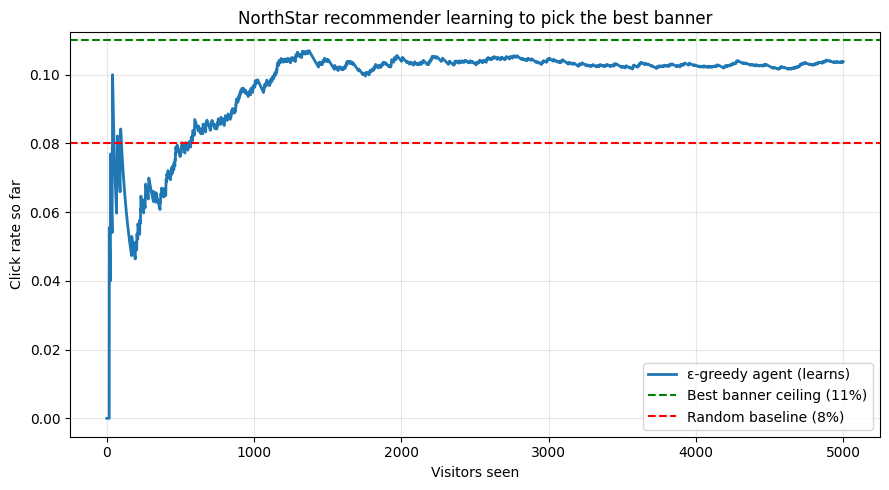

In [5]:
# Plot the running click rate as visitors arrive: does the agent get better over time?
def running_average(x):
    return np.cumsum(x) / (np.arange(len(x)) + 1)

plt.figure(figsize=(9, 5))
plt.plot(running_average(history), label="ε-greedy agent (learns)", linewidth=2)
plt.axhline(true_rates.max(), color="green", linestyle="--",
            label=f"Best banner ceiling ({true_rates.max():.0%})")
plt.axhline(true_rates.mean(), color="red", linestyle="--",
            label=f"Random baseline ({true_rates.mean():.0%})")
plt.xlabel("Visitors seen")
plt.ylabel("Click rate so far")
plt.title("NorthStar recommender learning to pick the best banner")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**That climbing blue line is reinforcement learning happening.** Early on the agent's scoreboard is based on only a handful of clicks, so its "best so far" is often wrong and its click rate sits near the random line. (It explores the same 10% of the time throughout — what changes is how *good* its exploit choices are.) As evidence piles up, the scoreboard sharpens, the agent commits to banner B, and the line rises toward the green ceiling. No labelled training set — it learned purely from the reward of each click.

You've now built one. Take a breath; in Part 3 we'll name every moving piece.

---
# Part 2 — Look at it: what just happened?
**⏱ ~10 minutes. Reflect before we theorise.**

Answer these for yourself (jot a sentence each), *then* run the cell to compare with Sarah's take.

1. Why did the agent show banner B so much more than A or C?
2. What would happen if `epsilon = 0` (never explore)? Could the agent get *stuck* on a banner that just got lucky early?
3. The agent never knew the true click rates. So what exactly did it "learn"?

In [6]:
print('''Sarah's reflection
------------------
1. The agent kept a running average click rate for each banner. B's average
   was highest, so on every "exploit" step (90% of the time) it picked B.
   Success feeds on itself.

2. With epsilon = 0 the agent never tries alternatives after its warm-up.
   If a weaker banner (say A) happened to get an early click by luck while B
   didn't, the agent would decide A is best and show ONLY A forever -- never
   discovering B is actually better. With click rates this low, that happens
   most of the time.
   A little exploration is insurance against bad luck. (Try it in Part 4!)

3. It did not learn "the rules of clicking". It learned a POLICY: a habit of
   which banner to show, tuned by reward, that gets better with experience.
   That trial-reward-adjust loop is the heartbeat of reinforcement learning.''')

Sarah's reflection
------------------
1. The agent kept a running average click rate for each banner. B's average
   was highest, so on every "exploit" step (90% of the time) it picked B.
   Success feeds on itself.

2. With epsilon = 0 the agent never tries alternatives after its warm-up.
   If a weaker banner (say A) happened to get an early click by luck while B
   didn't, the agent would decide A is best and show ONLY A forever -- never
   discovering B is actually better. With click rates this low, that happens
   most of the time.
   A little exploration is insurance against bad luck. (Try it in Part 4!)

3. It did not learn "the rules of clicking". It learned a POLICY: a habit of
   which banner to show, tuned by reward, that gets better with experience.
   That trial-reward-adjust loop is the heartbeat of reinforcement learning.


---
# Part 3 — Name it: the theory in plain English
**⏱ ~20 minutes. Now the words — each one maps to code you already ran.**

## The core loop

Every reinforcement learning system is the same loop, repeated thousands of times:

> An **agent** looks at its situation, takes an **action**, gets a **reward**, and **updates** how it will act next time.

That's it. Games, robots, self-driving cars, and the system that fine-tunes ChatGPT all run this same loop. Here is the vocabulary, each term tied to your banner code:

| Term | Plain English | In your code |
|---|---|---|
| **Agent** | The learner / decision-maker | Your `run_epsilon_greedy` function |
| **Environment** | The world it acts on | NorthStar's visitors (`show_banner`) |
| **Action** | A choice the agent can make | Which banner to show (A / B / C) |
| **Reward** | The feedback signal — bigger = better | `1` for a click, `0` for none |
| **Policy** | The agent's *strategy* for choosing actions | "90% show best, 10% explore" |
| **Value estimate** | The agent's belief about how good each action is | `estimated_rate` per banner |

**Real-world analogy — choosing a lunch spot.** You're new to an area with three cafés. Each visit is an *action*; how much you enjoy lunch is the *reward*. Go only to the first decent one you find and you might miss a better café next door (*no exploration*). Try a new place at random every single day and you waste good lunches on bad cafés (*too much exploration*). Sensible people mostly return to their favourite but occasionally try somewhere new. That sensible habit is a **policy**, and that's exactly what ε-greedy automates.

## The one tension that defines RL: explore vs. exploit

This is the idea worth remembering long after today:

- **Exploit** = use what you already know to get reward *now* (show the best-known banner).
- **Explore** = give up some reward now to *learn* something that pays off later (try another banner).

You can't do both at once, and getting the balance wrong is costly:

- **Too little exploration** → you lock onto a mediocre choice and never discover the better one (the `epsilon = 0` trap from Part 2).
- **Too much exploration** → you keep gambling on weak options and bleed reward.

`epsilon` is literally the knob for this trade-off. That's why this tiny algorithm is a genuine RL method, not a toy.

## How is this different from supervised learning (most of L01–L10)?

| | Supervised learning | Reinforcement learning |
|---|---|---|
| **What it's given** | A dataset of inputs *with correct answers* | No answer key — only rewards for what it tried |
| **Feedback** | "The right label was X" | "That choice earned 1" (never told the *best* choice) |
| **When feedback arrives** | All upfront, before deployment | Continuously, *while it acts* |
| **Sarah example** | Classify a review as positive/negative | Learn which banner earns clicks |

The crucial difference: supervised learning is told the right answer; **reinforcement learning is only told how good the answer it happened to pick was, and has to figure out the rest by trying.** That's why there's no training CSV here — the data is *generated by the agent's own choices.*

> **Key takeaway.** Reinforcement learning = learning a *policy* (a habit of acting) from *rewards* (feedback on actions), while balancing *exploration* against *exploitation*. Everything else is detail.

---
# Part 4 — Tinker: turn the dials
**⏱ ~15 minutes. Experiment — this is where intuition sticks.**

Run the experiments below and watch how behaviour changes. Predict the result *before* you run each one.

In [7]:
# Experiment A: compare different exploration levels.
# Predict first: which epsilon earns the most clicks over 5000 visitors?

for eps in [0.0, 0.01, 0.1, 0.5, 1.0]:
    # average over a few runs so luck doesn't fool us
    rates = []
    for _ in range(20):
        _, _, h = run_epsilon_greedy(n_visitors=5000, epsilon=eps)
        rates.append(h.mean())
    label = {0.0: "never explore", 1.0: "always random"}.get(eps, "")
    print(f"epsilon = {eps:<4}  ->  click rate {np.mean(rates):.2%}   {label}")

print("\nNotice: 0.0 is risky (can get stuck), 1.0 is just random,")
print("and a small-but-nonzero value usually wins. There's a sweet spot.")

epsilon = 0.0   ->  click rate 5.86%   never explore


epsilon = 0.01  ->  click rate 8.27%   


epsilon = 0.1   ->  click rate 10.16%   


epsilon = 0.5   ->  click rate 9.25%   


epsilon = 1.0   ->  click rate 7.95%   always random

Notice: 0.0 is risky (can get stuck), 1.0 is just random,
and a small-but-nonzero value usually wins. There's a sweet spot.


**What you should see:** the extremes lose. `epsilon = 1.0` is the random baseline (always exploring, never using what it learned). `epsilon = 0.0` is fragile — after its one-look warm-up it usually locks onto whichever banner got lucky first, and never corrects itself. A small value like `0.05`–`0.1` usually wins. That sweet spot *is* the explore/exploit balance from Part 3, made concrete.

Now make it your own. **Heads-up:** each run is random, so the agent won't find the best banner *every* time — especially when two banners are close. A miss isn't a bug; it's the explore/exploit trade-off showing up. Re-run and count how often it gets it right.

In [8]:
# Experiment B (your turn): change the world and see if the agent still copes.
# Try editing the numbers below, then re-run this cell.

# 1. Make banner C the best instead of B -- does the agent find it?
# 2. Make all three banners almost equal (e.g. 0.07, 0.075, 0.07) -- harder!
# 3. Add a fourth banner (you'd need to widen the arrays above too).

your_rates = np.array([0.05, 0.11, 0.08])   # <-- edit these
true_rates = your_rates                        # apply your world

counts, est, hist = run_epsilon_greedy(n_visitors=5000, epsilon=0.1)
winner = banners[int(np.argmax(est))]
print(f"With your click rates {your_rates.tolist()}:")
print(f"  The agent settled on: {winner}")
print(f"  Click rate achieved:  {hist.mean():.2%}")
print(f"  True best was:        {banners[int(np.argmax(your_rates))]}")
if int(np.argmax(est)) != int(np.argmax(your_rates)):
    print("\n  The agent picked the wrong banner this run! With only 10% exploration and")
    print("  rates this close, an early lucky streak can mislead it. Re-run the cell a few")
    print("  times -- how often does it get it right? Try epsilon=0.2 or more visitors.")

# reset to original world for any later cells
true_rates = np.array([0.05, 0.11, 0.08])

With your click rates [0.05, 0.11, 0.08]:
  The agent settled on: C · Trending now
  Click rate achieved:  8.46%
  True best was:        B · 50% off

  The agent picked the wrong banner this run! With only 10% exploration and
  rates this close, an early lucky streak can mislead it. Re-run the cell a few
  times -- how often does it get it right? Try epsilon=0.2 or more visitors.


---
# Part 5 — (Optional) Go deeper: add *context* and meet the Q-table
**⏱ ~20 minutes. Stretch material — skip if you're full.**

So far the agent showed the *same* best banner to everyone. But a first-time visitor and a loyal member probably respond to different banners. Real recommenders use **context** — something they know about the situation *before* choosing.

This upgrade has a name: a **contextual bandit**, and it's a half-step toward full reinforcement learning. The new idea is the **Q-table**: instead of one score per action, the agent keeps *a score per action for each kind of situation.* `Q` just means "estimated quality of taking this action in this situation."

NorthStar knows one thing about each visitor: are they a **new** visitor or a **returning** member? Watch the agent learn a *different* best banner for each.

In [9]:
# Two visitor types. Each type secretly responds best to a DIFFERENT banner.
# Rows = visitor type (0 = new, 1 = returning), Cols = banner A/B/C
true_rates_by_type = np.array([
    [0.04, 0.12, 0.06],   # NEW visitors love B (the discount)
    [0.10, 0.05, 0.13],   # RETURNING members love C (trending / loyalty)
])
visitor_types = ["new", "returning"]

def show_banner_ctx(visitor_type, banner_index):
    p = true_rates_by_type[visitor_type, banner_index]
    return 1 if rng.random() < p else 0

def run_contextual(n_visitors=8000, epsilon=0.1):
    # Q-table: one row of action-scores per visitor type
    Q = np.zeros((2, 3))
    counts = np.zeros((2, 3))
    for _ in range(n_visitors):
        vtype = rng.integers(0, 2)                 # observe the CONTEXT first
        if rng.random() < epsilon:
            choice = rng.integers(0, 3)            # explore
        else:
            choice = int(np.argmax(Q[vtype]))      # exploit best for THIS type
        reward = show_banner_ctx(vtype, choice)
        counts[vtype, choice] += 1
        Q[vtype, choice] += (reward - Q[vtype, choice]) / counts[vtype, choice]
    return Q

Q = run_contextual()
print("Learned Q-table (estimated click rate for each banner, per visitor type):\n")
print(f"{'':12s}{'A·New':>10s}{'B·50%off':>10s}{'C·Trend':>10s}   -> agent shows")
for t in range(2):
    best = banners[int(np.argmax(Q[t]))]
    print(f"{visitor_types[t]:12s}" + "".join(f"{Q[t,b]:>10.2%}" for b in range(3))
          + f"   -> {best}")
print("\nThe agent learned to show DIFFERENT banners to different visitors --")
print("entirely from clicks. That's a contextual bandit.")

Learned Q-table (estimated click rate for each banner, per visitor type):

                 A·New  B·50%off   C·Trend   -> agent shows
new              5.08%    11.58%    10.24%   -> B · 50% off
returning        9.66%     4.20%    13.52%   -> C · Trending now

The agent learned to show DIFFERENT banners to different visitors --
entirely from clicks. That's a contextual bandit.


### Where this leads (the one-paragraph map of full RL)

A contextual bandit chooses based on the *current* situation, but each choice is independent — showing a banner now doesn't change the *next* visitor. **Full reinforcement learning** adds one more idea: your action changes the *state* of the world, so you must think about **long-term** reward, not just the next click. A chess move, a robot step, or a multi-step checkout flow all work this way — a small sacrifice now can win later. The full-RL toolkit (Q-learning over states, policy gradients, deep RL) is just this same explore/learn/act loop scaled up to handle *sequences* of decisions. Notably, it's also how modern chatbots are tuned: **RLHF — reinforcement learning from human feedback** — asks people which of two answers they prefer, trains a *reward model* to predict those preferences, and then uses that reward to update the model's policy — the same act → reward → update loop you built in Part 1, at a vastly larger scale.

You don't need that machinery today. You've already built and understood the engine it's all based on.

---
## ✅ Session summary

| You learned | In one line |
|---|---|
| **The RL loop** | Agent → action → reward → update, repeated |
| **The 6 words** | agent, environment, action, reward, policy, value |
| **Explore vs exploit** | Trade reward-now against learning-for-later; `epsilon` is the dial |
| **RL vs supervised** | No answer key — the agent learns from the reward of what it tried |
| **Contextual bandit** | Use what you know about the situation; the Q-table holds a score per action *per context* |
| **Where it scales** | Sequences of decisions → full RL → RLHF behind modern chatbots |

**The mindset shift to keep:** supervised learning answers *"what is this?"* from labelled examples; reinforcement learning answers *"what should I do?"* from the consequences of trying. NorthStar's banner picker is small, but the loop inside it is the same one running the most advanced AI systems today.

> *"We never told it which banner was best. We just let it watch the clicks and it worked it out — and it keeps working it out as tastes change. That's the part I didn't think was possible."* — Sarah, after the homepage relaunch.